# Key-rate curve and covariance (prototype)

Fit a zero curve to CRSP Treasuries each day, read off the 8 key rates (6M, 1Y, 2Y, 3Y, 5Y, 7Y, 10Y, 30Y), then estimate the 8x8 covariance of daily yield changes (deliverable 3, section 2.1). Prototype only, to be moved to `src/` once checked.

Needs `matplotlib` and `scipy` (scipy is already installed via scikit-learn). `matplotlib` is not in `pyproject.toml` yet.

In [1]:
import logging
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # repo root, so `src` imports

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

from src.data import pull_treasuries

logging.basicConfig(level=logging.WARNING, format="%(message)s")

START, END = "2024-01-01", "2024-01-31"  # only the cached range
KEYS = np.array([0.5, 1, 2, 3, 5, 7, 10, 30])
LABELS = ["6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "30Y"]

## Load and filter

Keep bonds, notes and bills (`security_type` 1, 2, 4). Types 11 and 12 are TIPS (real yields), so they are dropped, as are issues under 0.1y to maturity. Dirty price is `mid_price + accrued_interest`.

In [2]:
raw = pull_treasuries(START, END)
raw["security_type"].value_counts().sort_index()

security_type
1     1995
2     5076
4     1083
11     462
12     632
Name: count, dtype: int64

## Curve fit

Nelson-Siegel-Svensson zero curve (continuously compounded), fitted per day by least squares on dirty prices. Residuals are weighted by roughly 1/maturity so price errors behave like yield errors. Cashflows are semiannual coupons backward from maturity; bills pay 100 at maturity.

In [3]:
def cashflows(row):
    """Times (years from row.date) and amounts per 100 face."""
    t0, mat = row.date, row.maturity_date
    ttm = (mat - t0).days / 365.25
    if row.coupon_rate == 0 or row.security_type == 4:
        return np.array([ttm]), np.array([100.0])
    times, d, k = [], mat, 0
    while d > t0:
        times.append((d - t0).days / 365.25)
        k += 1
        d = mat - pd.DateOffset(months=6 * k)
    cf = np.full(len(times), float(row.coupon_rate) / 2)
    cf[0] += 100  # times[0] is the maturity
    return np.array(times[::-1]), cf[::-1]


def nss_zero(t, b):
    b0, b1, b2, b3, l1, l2 = b
    t = np.maximum(t, 1e-6)
    f1 = (1 - np.exp(-t / l1)) / (t / l1)
    f2 = (1 - np.exp(-t / l2)) / (t / l2)
    return b0 + b1 * f1 + b2 * (f1 - np.exp(-t / l1)) + b3 * (f2 - np.exp(-t / l2))


def fit_day(day):
    day = day[day.security_type.isin([1, 2, 4])].copy()
    day["ttm"] = (day.maturity_date - day.date).dt.days / 365.25
    day = day[day.ttm > 0.1]
    dirty = (day.mid_price + day.accrued_interest).astype(float).values
    cfs = [cashflows(r) for r in day.itertuples()]
    w = 1 / np.maximum(day.ttm.values * 0.9, 0.25)

    def resid(b):
        model = np.array([(c * np.exp(-nss_zero(t, b) * t)).sum() for t, c in cfs])
        return (model - dirty) * w

    lo = [0, -0.2, -0.2, -0.2, 0.2, 2.0]
    hi = [0.15, 0.2, 0.2, 0.2, 5.0, 30.0]
    fit = least_squares(resid, [0.04, 0, 0, 0, 1.5, 8.0], bounds=(lo, hi))
    zero = np.exp(nss_zero(KEYS, fit.x)) - 1  # annual effective
    rmse = np.sqrt(np.mean((resid(fit.x) / w) ** 2))
    return fit.x, zero, rmse, len(cfs)

In [4]:
params, zeros, diag = {}, {}, {}
for date, day in raw.groupby("date"):
    params[date], zeros[date], rmse, n = fit_day(day)
    diag[date] = {"bonds": n, "price_rmse": rmse}

Y = pd.DataFrame(zeros, index=LABELS).T  # one row per date, decimal
Y.index.name = "date"
pd.DataFrame(diag).T.describe().loc[["min", "mean", "max"]]

,bonds,price_rmse
min,370.000000,0.377851
mean,372.333333,0.420885
max,374.000000,0.470601


## Sanity check

Compare against published Treasury par yields for a few dates before trusting the fit. Par yield from the fitted curve (semiannual) at the standard tenors:

In [5]:
def par_yield(b, T):
    s = np.arange(0.5, T + 1e-9, 0.5)
    df = np.exp(-nss_zero(s, b) * s)
    return 2 * (1 - df[-1]) / df.sum()

par = pd.DataFrame(
    {d: {f"{T}Y": par_yield(b, T) * 100 for T in (2, 5, 10, 30)} for d, b in params.items()}
).T
par.iloc[[0, len(par) // 2, -1]].round(2)

,2Y,5Y,10Y,30Y
2024-01-02,4.33,3.93,4.00,4.20
2024-01-17,4.35,4.04,4.17,4.44
2024-01-31,4.21,3.85,3.97,4.29


## Yield curve over time

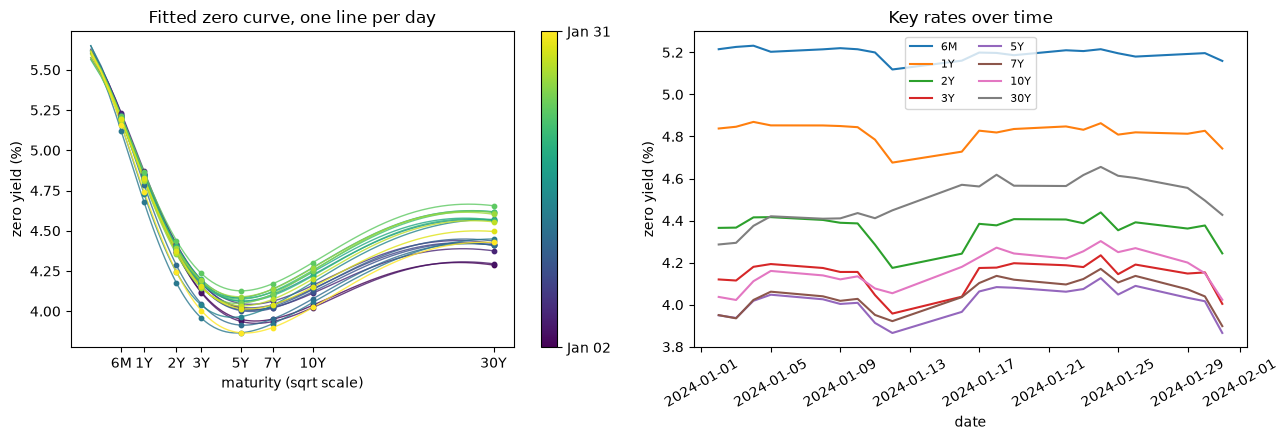

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

colors = plt.cm.viridis(np.linspace(0, 1, len(Y)))
grid = np.linspace(0.1, 30, 300)
for (date, row), c in zip(Y.iterrows(), colors):
    curve = np.exp(nss_zero(grid, params[date])) - 1
    ax1.plot(grid, curve * 100, color=c, lw=1, alpha=0.8)
    ax1.scatter(KEYS, row.values * 100, color=c, s=10, zorder=3)
ax1.set_xscale("function", functions=(np.sqrt, np.square))
ax1.set_xticks(KEYS, LABELS)
ax1.set(xlabel="maturity (sqrt scale)", ylabel="zero yield (%)", title="Fitted zero curve, one line per day")
sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(0, len(Y) - 1))
cb = fig.colorbar(sm, ax=ax1, ticks=[0, len(Y) - 1])
cb.ax.set_yticklabels([f"{Y.index[0]:%b %d}", f"{Y.index[-1]:%b %d}"])

for lab in LABELS:
    ax2.plot(Y.index, Y[lab] * 100, label=lab)
ax2.set(xlabel="date", ylabel="zero yield (%)", title="Key rates over time")
ax2.legend(ncol=2, fontsize=8)
ax2.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## Covariance of key-rate changes

Plain sample covariance of daily changes, in bp^2. With one month there are about 20 observations, so this is noisy. Use the full history before choosing an estimator (sample, EWMA, Ledoit-Wolf).

20 daily changes


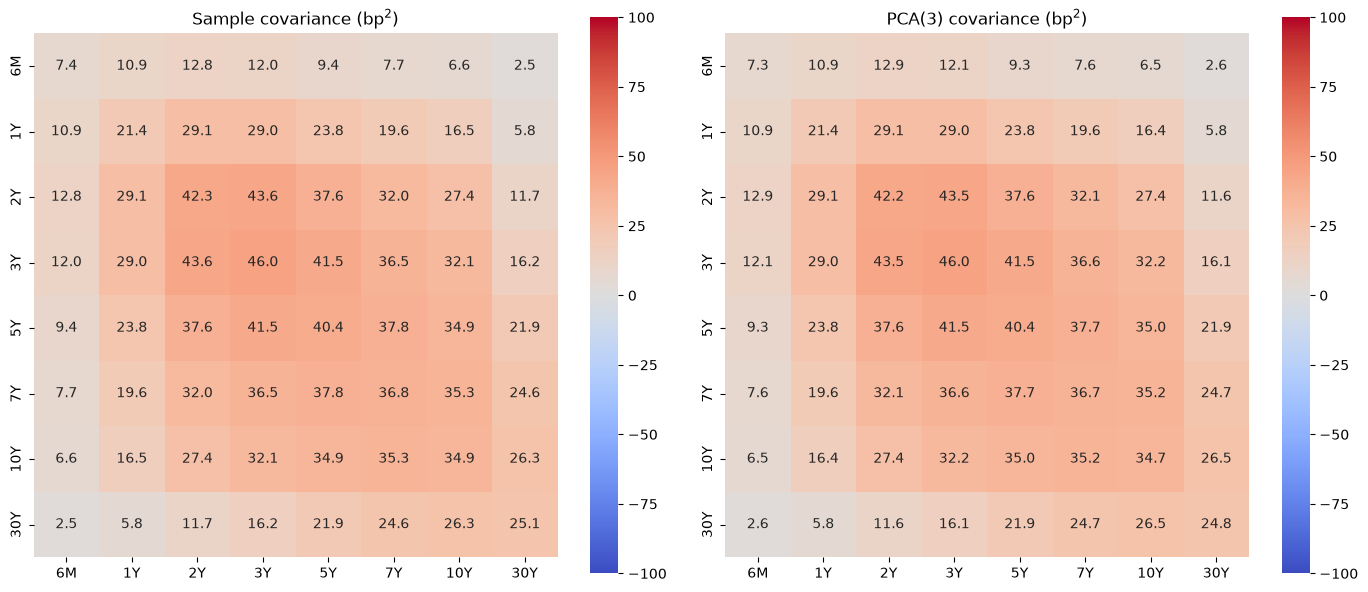

In [12]:
import seaborn as sns

dY = Y.diff().dropna()
Sigma = dY.cov() * 1e8  # bp^2
print(f"{len(dY)} daily changes")

# rank-3 PCA approximation: Gamma_p Lambda_p Gamma_p'
P = 3
eigval, eigvec = np.linalg.eigh(Sigma.values)
eigval, eigvec = eigval[::-1], eigvec[:, ::-1]
Sigma_pca = pd.DataFrame(
    eigvec[:, :P] @ np.diag(eigval[:P]) @ eigvec[:, :P].T, index=LABELS, columns=LABELS
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, M, title in [(axes[0], Sigma, "Sample covariance"), (axes[1], Sigma_pca, f"PCA({P}) covariance")]:
    sns.heatmap(M, annot=True, fmt=".1f", cmap="coolwarm", center=0, square=True,
                vmin=-100, vmax=100, ax=ax)
    ax.set_title(f"{title} (bp$^2$)")
fig.tight_layout()
plt.show()

20 daily changes


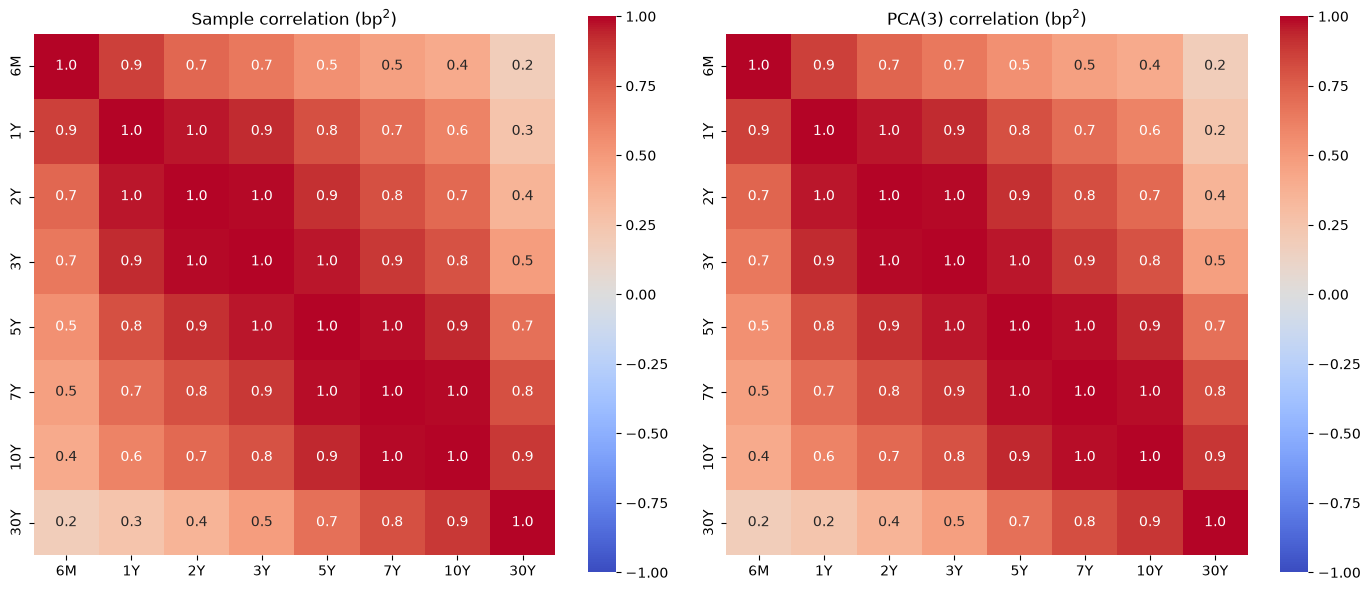

In [15]:
import seaborn as sns

dY = Y.diff().dropna()
Sigma = dY.corr()  # bp^2
print(f"{len(dY)} daily changes")

# rank-3 PCA approximation: Gamma_p Lambda_p Gamma_p'
P = 3
eigval, eigvec = np.linalg.eigh(Sigma.values)
eigval, eigvec = eigval[::-1], eigvec[:, ::-1]
Sigma_pca = pd.DataFrame(
    eigvec[:, :P] @ np.diag(eigval[:P]) @ eigvec[:, :P].T, index=LABELS, columns=LABELS
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, M, title in [(axes[0], Sigma, "Sample correlation"), (axes[1], Sigma_pca, f"PCA({P}) correlation")]:
    sns.heatmap(M, annot=True, fmt=".1f", cmap="coolwarm", center=0, square=True,
                vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"{title} (bp$^2$)")
fig.tight_layout()
plt.show()

share of variance: [0.84  0.138 0.02  0.002 0.001 0.    0.    0.   ]


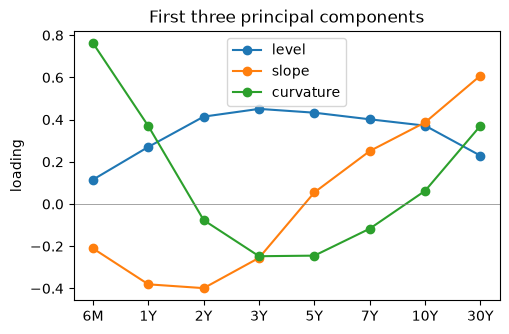

In [9]:
print("share of variance:", np.round(eigval / eigval.sum(), 3))

fig, ax = plt.subplots(figsize=(5.5, 3.5))
for i, name in enumerate(["level", "slope", "curvature"]):
    ax.plot(LABELS, eigvec[:, i] * np.sign(eigvec[:, i].sum() or 1), marker="o", label=name)
ax.axhline(0, color="grey", lw=0.5)
ax.set(title="First three principal components", ylabel="loading")
ax.legend()
plt.show()